In [1]:
import pandas as pd
import numpy as np
import sqlite3

df = pd.read_csv(r"C:\Users\sofya\OneDrive\Olympiad_analysis\data\olympiad_results.csv")
df.head()
df.shape
df.info()
df.columns
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8037 entries, 0 to 8036
Data columns (total 46 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   student_id          8037 non-null   object 
 1   region              8037 non-null   object 
 2   school_number       8037 non-null   int64  
 3   grade               8037 non-null   int64  
 4   start_time          8037 non-null   object 
 5   end_time            8037 non-null   object 
 6   Task_1_answer       7719 non-null   float64
 7   Task_1_correct      7719 non-null   float64
 8   Task_1_time_spent   7719 non-null   float64
 9   Task_2_answer       7696 non-null   float64
 10  Task_2_correct      7696 non-null   float64
 11  Task_2_time_spent   7696 non-null   float64
 12  Task_3_answer       7722 non-null   float64
 13  Task_3_correct      7722 non-null   float64
 14  Task_3_time_spent   7722 non-null   float64
 15  Task_4_answer       7727 non-null   float64
 16  Task_4

,school_number,grade,Task_1_answer,Task_1_correct,Task_1_time_spent,Task_2_answer,Task_2_correct,Task_2_time_spent,Task_3_answer,Task_3_correct,...,Task_10_time_spent,Task_11_answer,Task_11_correct,Task_11_time_spent,Task_12_answer,Task_12_correct,Task_12_time_spent,total_score,attempts_count,disconnects
count,8037.000000,8037.000000,7719.000000,7719.000000,7719.000000,7696.000000,7696.000000,7696.000000,7722.000000,7722.000000,...,7721.000000,7750.000000,7750.000000,7750.000000,7716.00000,7716.000000,7716.000000,8037.000000,8037.000000,8037.000000
mean,29.989797,8.009830,2.509522,0.296671,63.525327,2.491294,0.377469,68.488046,2.518519,0.337218,...,75.193498,2.498323,0.465161,72.092516,2.51633,0.567911,77.140747,5.522210,1.489735,0.192485
std,17.184086,1.997205,1.120323,0.456820,25.438295,1.116793,0.484785,25.352555,1.109814,0.472791,...,25.606718,1.128788,0.498817,25.882520,1.11903,0.495399,25.900155,2.783978,0.499926,0.441617
min,1.000000,5.000000,1.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,0.000000,...,1.000000,1.000000,0.000000,1.000000,1.00000,0.000000,1.000000,0.000000,1.000000,0.000000
25%,15.000000,6.000000,1.000000,0.000000,47.000000,2.000000,0.000000,52.000000,2.000000,0.000000,...,58.000000,1.000000,0.000000,55.000000,2.00000,0.000000,60.000000,3.000000,1.000000,0.000000
50%,30.000000,8.000000,3.000000,0.000000,63.000000,2.000000,0.000000,69.000000,3.000000,0.000000,...,75.000000,3.000000,0.000000,72.000000,3.00000,1.000000,77.000000,5.000000,1.000000,0.000000
75%,45.000000,10.000000,4.000000,1.000000,81.000000,3.000000,1.000000,86.000000,4.000000,1.000000,...,92.000000,4.000000,1.000000,89.000000,4.00000,1.000000,94.000000,8.000000,2.000000,0.000000
max,59.000000,11.000000,4.000000,1.000000,167.000000,4.000000,1.000000,150.000000,4.000000,1.000000,...,164.000000,4.000000,1.000000,172.000000,4.00000,1.000000,191.000000,12.000000,2.000000,4.000000


data validation

In [2]:
duplicate_rows = df[df.duplicated(keep=False)]
duplicate_rows = duplicate_rows.sort_values("student_id")

duplicate_rows.head(10)
df_clean = df.drop_duplicates().copy()

# нормализация регионов
region_map = {
    "уфа": "Уфа",
    "воронеж": "Воронеж",
    "краснодар": "Краснодар",
    "ростов-на-дону": "Ростов-на-Дону",
    "новосибирск": "Новосибирск",
    "пермь": "Пермь",
    "екатеринбург": "Екатеринбург",
    "казань": "Казань",
    "г.казань": "Казань",
    "москва": "Москва",
    "г. москва": "Москва",
    "мск": "Москва",
    "moskva": "Москва",
    "санкт-петербург": "Санкт-Петербург",
    "санкт петербург": "Санкт-Петербург",
    "спб": "Санкт-Петербург"}
df_clean["region_clean"] = (df_clean["region"] .astype("string") .str.strip() .str.lower() .replace(region_map))


# продолжительность сессии
df_clean["start_time"] = pd.to_datetime(df_clean["start_time"])
df_clean["end_time"] = pd.to_datetime(df_clean["end_time"])

df_clean["session_duration_sec"] = (
    df_clean["end_time"] - df_clean["start_time"]
).dt.total_seconds()

df_clean["session_duration_min"] = (
    df_clean["session_duration_sec"] / 60
)
# подозрительные короткие сессии маркируем 
df_clean["is_fast_session_under_1min"] = (
    df_clean["session_duration_sec"] < 60
)


df_clean["is_fast_session_under_1min"].sum()
print(df_clean["is_fast_session_under_1min"])
df_clean.to_csv(
    "../data/olympiad_results_cleaned.csv",
    index=False
)

# соответствие баллов
task_correct = [
    f"Task_{i}_correct"
    for i in range(1, 13)
]

calculated_score = df[task_correct].sum(axis=1)

mismatches = (
    calculated_score != df["total_score"]
).sum()

print(mismatches)

0       False
1       False
2       False
3       False
4       False
        ...  
8032    False
8033    False
8034    False
8035    False
8036    False
Name: is_fast_session_under_1min, Length: 8000, dtype: bool
0


In [3]:
import sqlite3

connection = sqlite3.connect("../data/olympiad_results_cleaned.db")

df_clean.to_sql(
    "olympiad_results",
    connection, 
    if_exists="replace",
    index=False
)

query = """
SELECT *
FROM olympiad_results
LIMIT 5;
"""

sql_result = pd.read_sql_query(query, connection)

sql_result

,student_id,region,school_number,grade,start_time,end_time,Task_1_answer,Task_1_correct,Task_1_time_spent,Task_2_answer,...,Task_12_correct,Task_12_time_spent,total_score,device_type,attempts_count,disconnects,region_clean,session_duration_sec,session_duration_min,is_fast_session_under_1min
0,S200000,Краснодар,9,11,2026-04-10 11:10:00,2026-04-10 11:25:19,4.0,0.0,93.0,1.0,...,0.0,124.0,3,desktop,2,0,Краснодар,919.0,15.316667,0
1,S200001,Ростов-на-Дону,44,9,2026-04-10 10:30:00,2026-04-10 10:44:19,3.0,0.0,105.0,2.0,...,0.0,63.0,6,mobile,2,0,Ростов-на-Дону,859.0,14.316667,0
2,S200002,Екатеринбург,44,9,2026-04-10 10:25:00,2026-04-10 10:38:33,4.0,1.0,60.0,3.0,...,1.0,77.0,7,mobile,1,1,Екатеринбург,813.0,13.550000,0
3,S200003,Казань,44,11,2026-04-10 10:04:00,2026-04-10 10:18:18,1.0,0.0,58.0,1.0,...,1.0,86.0,5,mobile,1,0,Казань,858.0,14.300000,0
4,S200004,Уфа,26,9,2026-04-10 10:53:00,2026-04-10 11:08:36,4.0,0.0,111.0,1.0,...,0.0,96.0,6,mobile,2,0,Уфа,936.0,15.600000,0


In [4]:
conn = sqlite3.connect("../data/olympiad_results_cleaned.db")
def sql(q: str) -> pd.DataFrame:
    return pd.read_sql_query(q, conn)


    
sql("""SELECT 
      region_clean, COUNT(*) AS participants, ROUND(AVG(total_score), 2) AS avg_score,
      MAX(total_score) AS max_score, MIN(total_score) AS min_score
FROM olympiad_results
GROUP BY region_clean
ORDER BY avg_score DESC;
""")

,region_clean,participants,avg_score,max_score,min_score
0,Новосибирск,786,5.71,12,0
1,Москва,830,5.63,12,0
2,Екатеринбург,751,5.61,12,0
3,Санкт-Петербург,801,5.56,12,0
4,Ростов-на-Дону,796,5.56,12,0
5,Уфа,843,5.48,12,0
6,Воронеж,803,5.47,12,0
7,Казань,821,5.46,12,0
8,Краснодар,806,5.41,12,0
9,Пермь,763,5.35,12,0


зависит ли средний результат олимпиады от класса участника

In [5]:
query = """
SELECT grade,
    COUNT(*) AS participants,
    AVG(total_score) AS avg_score,
    MIN(total_score) AS min_score,
    MAX(total_score) AS max_score,
    100.0 * SUM(CASE WHEN total_score = 12 THEN 1 ELSE 0 END) / COUNT(*) AS perfect_score_pct
    FROM olympiad_results
    GROUP BY grade
    ORDER BY grade;
"""
grade_analysis = pd.read_sql_query(query, connection)
grade_analysis['avg_score'] = grade_analysis['avg_score'].round(2)
grade_analysis['perfect_score_pct'] = grade_analysis['perfect_score_pct'].round(2)
grade_analysis

,grade,participants,avg_score,min_score,max_score,perfect_score_pct
0,5,1105,4.48,0,12,0.27
1,6,1173,4.82,0,12,0.51
2,7,1170,5.22,0,12,0.34
3,8,1110,5.44,0,12,0.54
4,9,1131,5.88,0,12,1.15
5,10,1165,6.19,0,12,1.12
6,11,1146,6.60,0,12,2.01


Анализ школ

In [6]:
query = """
SELECT 
    region_clean, school_number,
    COUNT(*) AS participants,
    AVG(total_score) AS avg_score,
    MAX(total_score) AS max_score
FROM olympiad_results
GROUP BY region_clean, school_number
HAVING COUNT(*) >= 10
ORDER BY avg_score DESC
LIMIT 15;
"""
rating_school = pd.read_sql_query(query, connection)
rating_school['avg_score'] = rating_school['avg_score'].round(2)
rating_school

,region_clean,school_number,participants,avg_score,max_score
0,Ростов-на-Дону,13,20,7.95,11
1,Санкт-Петербург,11,12,7.92,10
2,Ростов-на-Дону,4,13,7.77,12
3,Москва,26,10,7.50,11
4,Новосибирск,52,10,7.50,12
5,Санкт-Петербург,56,10,7.40,12
6,Москва,4,14,7.36,11
7,Пермь,48,14,7.29,12
8,Новосибирск,6,12,7.25,12
9,Казань,5,22,7.18,12


Влияет ли отключение на результаты

In [10]:
query = """ 
SELECT disconnects, 
     COUNT(*) AS participants,
     AVG(total_score) AS avg_score,
     AVG(session_duration_min) AS
avg_duration
FROM olympiad_results
GROUP BY disconnects
ORDER BY disconnects;
"""
corr_time_results = pd.read_sql_query(query, connection)
corr_time_results['avg_score'] = corr_time_results['avg_score'].round(2)
corr_time_results['avg_duration'] = corr_time_results['avg_duration'].round(2)
corr_time_results

,disconnects,participants,avg_score,avg_duration
0,0,6604,5.51,13.99
1,1,1263,5.56,14.01
2,2,122,5.96,14.02
3,3,10,5.70,13.88
4,4,1,5.00,15.57


Анализ сложности заданий

In [11]:
task_queries = []

for i in range(1, 13):

    query_part = f"""
    SELECT
        {i} AS task_number,

        COUNT(*) AS total_participants,

        SUM(
            CASE WHEN Task_{i}_correct IS NOT NULL
            THEN 1 ELSE 0 END
        ) AS answered,

        SUM(
            CASE WHEN Task_{i}_correct IS NULL
            THEN 1 ELSE 0 END
        ) AS skipped,

        ROUND(
            AVG(Task_{i}_correct) * 100, 2
        ) AS correct_rate_pct,

        ROUND(
            AVG(Task_{i}_time_spent), 2
        ) AS avg_time_sec,

        ROUND(
            AVG(
                CASE WHEN Task_{i}_correct = 1
                THEN Task_{i}_time_spent END
            ), 2
        ) AS avg_time_correct_sec,

        ROUND(
            AVG(
                CASE WHEN Task_{i}_correct = 0
                THEN Task_{i}_time_spent END
            ), 2
        ) AS avg_time_incorrect_sec

    FROM olympiad_results
    """

    task_queries.append(query_part)

full_query = " UNION ALL ".join(task_queries)

full_query += " ORDER BY correct_rate_pct ASC;"

task_analysis = pd.read_sql_query(
    full_query,
    connection
)

task_analysis

,task_number,total_participants,answered,skipped,correct_rate_pct,avg_time_sec,avg_time_correct_sec,avg_time_incorrect_sec
0,1,8000,7682,318,29.69,63.55,63.19,63.70
1,9,8000,7691,309,31.88,65.30,65.78,65.08
2,3,8000,7686,314,33.72,65.45,66.01,65.16
3,2,8000,7660,340,37.74,68.51,68.24,68.67
4,6,8000,7674,326,44.89,71.06,71.25,70.91
5,11,8000,7714,286,46.46,72.09,72.58,71.67
6,10,8000,7685,315,52.97,75.19,75.24,75.12
7,12,8000,7683,317,56.85,77.14,77.55,76.59
8,7,8000,7691,309,58.34,78.35,78.77,77.75
9,4,8000,7693,307,58.87,78.07,78.11,78.02


In [ ]:
Визуализация

Text(0.5, 0, 'task number')

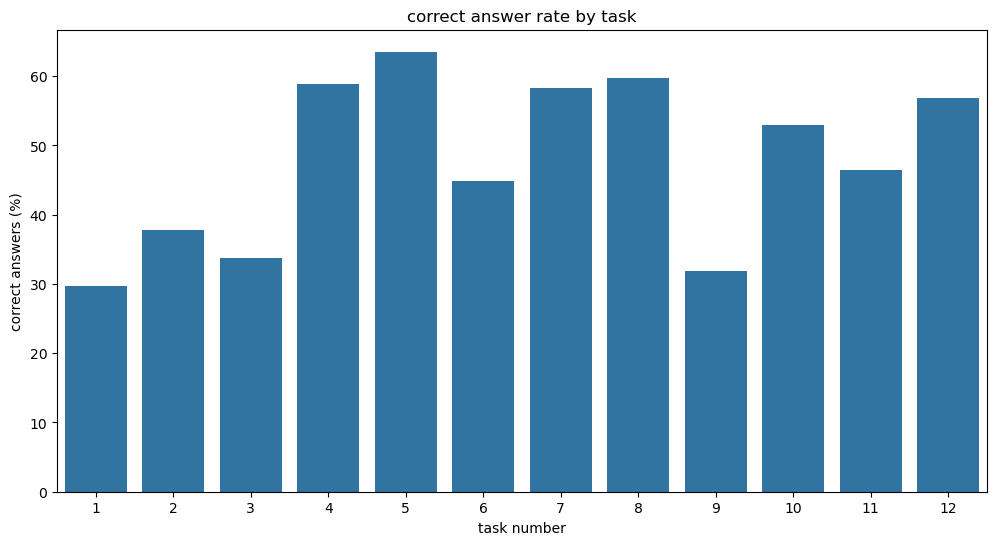

In [16]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12,6))

sns.barplot(
    data=task_analysis,
    x="task_number",
    y="correct_rate_pct"
)
plt.title("correct answer rate by task")
plt.ylabel("correct answers (%)")
plt.xlabel("task number")

Text(0.5, 0, 'task number')

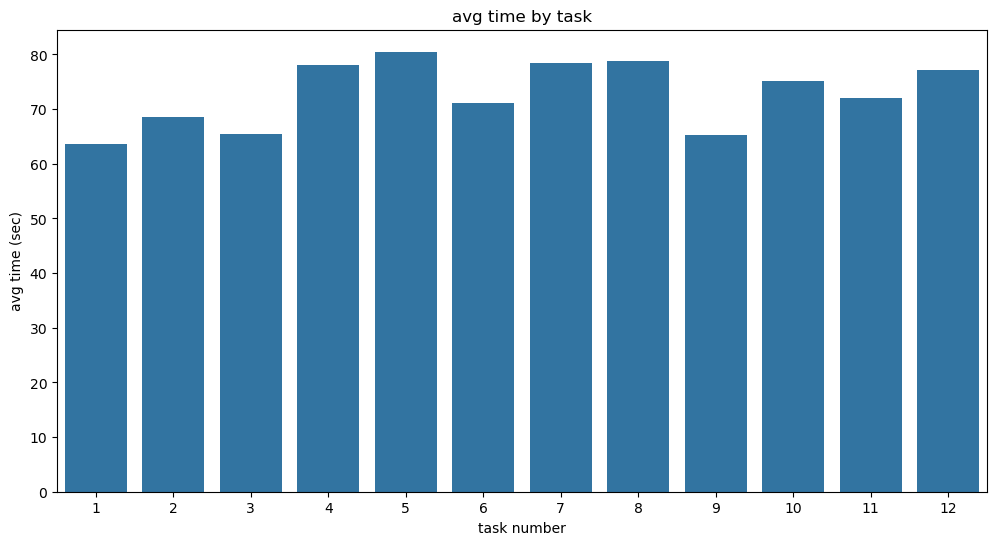

In [17]:
plt.figure(figsize=(12,6))

sns.barplot(
    data=task_analysis,
    x="task_number",
    y="avg_time_sec"
)

plt.title("avg time by task")
plt.ylabel("avg time (sec)")
plt.xlabel("task number")

Средний балл по классам

In [19]:
query = """
SELECT grade,
    COUNT(*) AS participants,
    AVG(total_score) AS avg_score,

    100.0 * SUM(
    CASE WHEN total_score = 12
    THEN 1 ELSE 0 END
) / COUNT(*)  AS perfect_score_pct
FROM olympiad_results
GROUP BY grade
ORDER BY grade;
"""
avg_class_results = pd.read_sql_query(query, connection)
avg_class_results

,grade,participants,avg_score,perfect_score_pct
0,5,1105,4.476923,0.271493
1,6,1173,4.822677,0.511509
2,7,1170,5.221368,0.341880
3,8,1110,5.440541,0.540541
4,9,1131,5.881521,1.149425
5,10,1165,6.190558,1.115880
6,11,1146,6.598604,2.006981


Отчет для любого региона

In [29]:
def get_region_report(region_name, connection):
    # общ статистика по реогиону
    summary_query = """
    SELECT
        region_clean,
        COUNT(*) AS participants,
        AVG(total_score) AS avg_score,
        MAX(total_score) AS max_score,
        MIN(total_score) AS min_score,
        AVG(session_duration_sec) AS avg_duration
    FROM olympiad_results
    WHERE region_clean = ?
    GROUP BY region_clean
    """

    summary = pd.read_sql_query(summary_query, connection, params=(region_name,)
                               )
    # распределение по классам
    grades_query = """
    SELECT grade,
        COUNT(*) AS participants,
        AVG(total_score) AS avg_score
    FROM olympiad_results
    WHERE region_clean = ?
    GROUP BY grade
    ORDER BY grade
    """

    grades = pd.read_sql_query(
        grades_query,
        connection,
        params=(region_name,)
    )
    # результаты по устройствам
    devices_query = """
    SELECT
        device_type,
        COUNT(*) AS participants,
        AVG(total_score) AS avg_score
    FROM olympiad_results
    WHERE region_clean = ?
    GROUP BY device_type
    ORDER BY avg_score DESC
    """

    devices = pd.read_sql_query(
        devices_query,
        connection,
        params=(region_name,)
    )

    # рейтинг школ
    schools_query = """
    SELECT
        school_number,
        COUNT(*) AS participants,
        AVG(total_score) AS avg_score
    FROM olympiad_results
    WHERE region_clean = ?
    GROUP BY school_number
    HAVING COUNT(*) >= 10
    ORDER BY avg_score DESC
    LIMIT 10
    """

    schools = pd.read_sql_query(
        schools_query,
        connection,
        params=(region_name,)
    )

    return {
        "summary": summary,
        "grades": grades,
        "devices": devices,
        "schools": schools
}

In [30]:
moscow_report = get_region_report("Москва",connection)

print("ОБЩАЯ СТАТИСТИКА")
display(moscow_report["summary"])

print("ПО КЛАССАМ")
display(moscow_report["grades"])

print("ПО УСТРОЙСТВАМ")
display(moscow_report["devices"])

print("ТОП ШКОЛ")
display(moscow_report["schools"])
    
    

ОБЩАЯ СТАТИСТИКА


,region_clean,participants,avg_score,max_score,min_score,avg_duration
0,Москва,830,5.627711,12,0,840.336145


ПО КЛАССАМ


,grade,participants,avg_score
0,5,129,4.728682
1,6,113,4.893805
2,7,122,5.221311
3,8,116,5.793103
4,9,134,6.052239
5,10,108,6.305556
6,11,108,6.546296


ПО УСТРОЙСТВАМ


,device_type,participants,avg_score
0,tablet,48,5.770833
1,desktop,475,5.621053
2,mobile,307,5.615635


ТОП ШКОЛ


,school_number,participants,avg_score
0,26,10,7.500000
1,4,14,7.357143
2,43,12,6.833333
3,34,19,6.789474
4,28,16,6.750000
5,2,11,6.727273
6,22,25,6.520000
7,12,15,6.333333
8,24,14,6.285714
9,6,21,6.285714


In [33]:
from scipy import stats
import pandas as pd


region_groups = [g["total_score"].dropna() for _, g in df_clean.groupby("region_clean")]
anova_region = stats.f_oneway(*region_groups)

grade_groups = [g["total_score"].dropna() for _, g in df_clean.groupby("grade")]
anova_grade = stats.f_oneway(*grade_groups)

device_groups = [g["total_score"].dropna() for _, g in df_clean.groupby("device_type")]
anova_device = stats.f_oneway(*device_groups)

duration_score = df_clean[["session_duration_min", "total_score"]].dropna()
pearson = stats.pearsonr(duration_score["session_duration_min"], duration_score["total_score"])

disconnect_score = df_clean[["disconnects", "total_score"]].dropna()
pearson_disc = stats.pearsonr(disconnect_score["disconnects"], disconnect_score["total_score"])

#ФОРМИРУЕМ ТАБЛИЦУ
alpha = 0.05

def interpret_pvalue(p_value):
    return "Обнаружены" if p_value < alpha else "Не обнаружены"

def interpret_correlation(r_value, p_value):
    if p_value >= alpha:
        return "Связь не обнаружена"
    abs_r = abs(r_value)
    if abs_r < 0.3: strength = "Слабая"
    elif abs_r < 0.7: strength = "Умеренная"
    else: strength = "Сильная"
    direction = "положительная" if r_value > 0 else "отрицательная"
    return f"{strength} {direction} связь"

results = [
    {"Исследование": "Различия между регионами", "Тест": "ANOVA", "p-value": round(anova_region.pvalue, 4), "Вывод": interpret_pvalue(anova_region.pvalue)},
    {"Исследование": "Различия между классами", "Тест": "ANOVA", "p-value": round(anova_grade.pvalue, 4), "Вывод": interpret_pvalue(anova_grade.pvalue)},
    {"Исследование": "Различия между устройствами", "Тест": "ANOVA", "p-value": round(anova_device.pvalue, 4), "Вывод": interpret_pvalue(anova_device.pvalue)},
    {"Исследование": "Время и итоговый балл", "Тест": "Pearson", "p-value": round(pearson[1], 4), "Вывод": interpret_correlation(pearson[0], pearson[1])},
    {"Исследование": "Отключения и итоговый балл", "Тест": "Pearson", "p-value": round(pearson_disc[1], 4), "Вывод": interpret_correlation(pearson_disc[0], pearson_disc[1])}
]

summary_table = pd.DataFrame(results)



display(
    summary_table.style
    .set_caption("таблица статистических гипотез")
    .set_properties(**{'text-align': 'left'})
    .hide(axis="index")
)

Исследование,Тест,p-value,Вывод
Различия между регионами,ANOVA,0.291900,Не обнаружены
Различия между классами,ANOVA,0.000000,Обнаружены
Различия между устройствами,ANOVA,0.817000,Не обнаружены
Время и итоговый балл,Pearson,0.000000,Слабая положительная связь
Отключения и итоговый балл,Pearson,0.169300,Связь не обнаружена


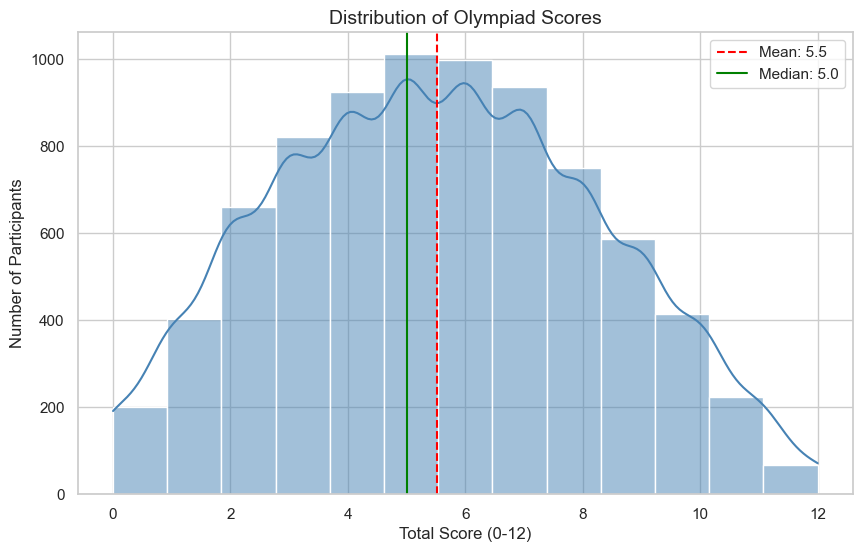

C:\Users\sofya\AppData\Local\Temp\ipykernel_113240\3890382222.py:33: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x="region_clean", y="total_score", palette="Set3")


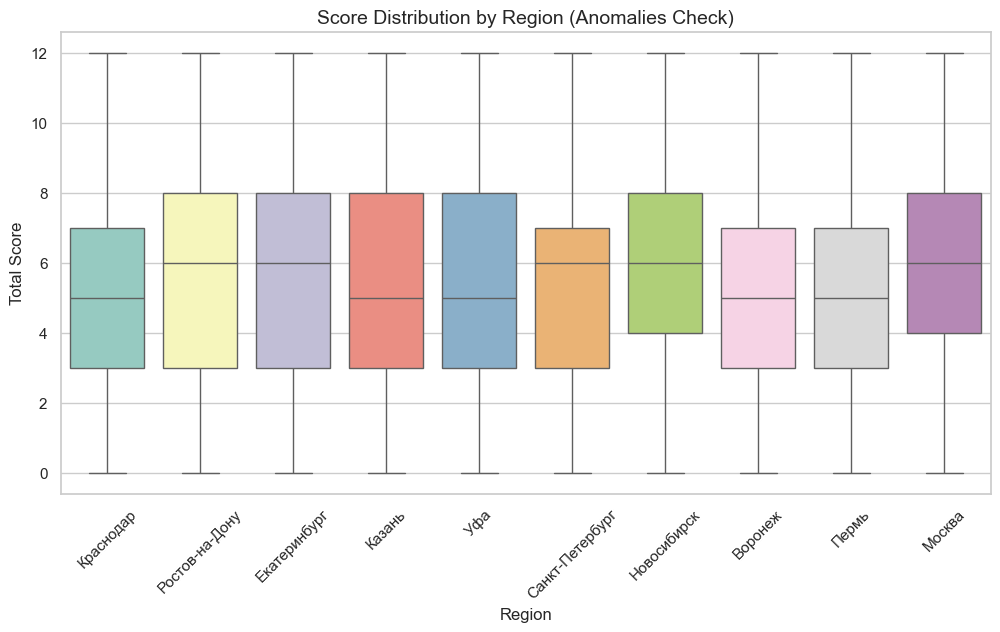

C:\Users\sofya\AppData\Local\Temp\ipykernel_113240\3890382222.py:52: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=region_scores, x="total_score", y="region_clean", palette="viridis")


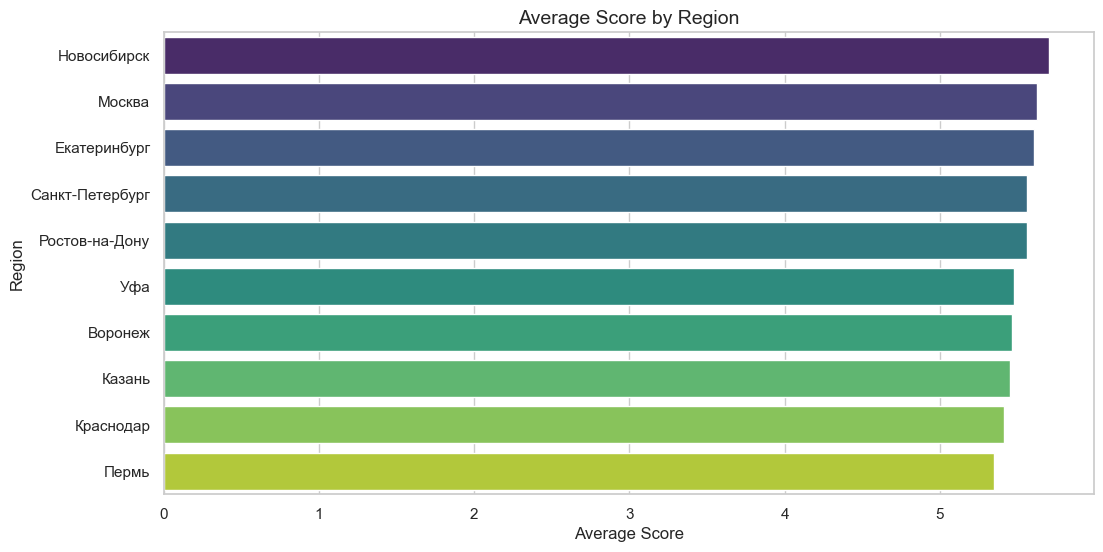

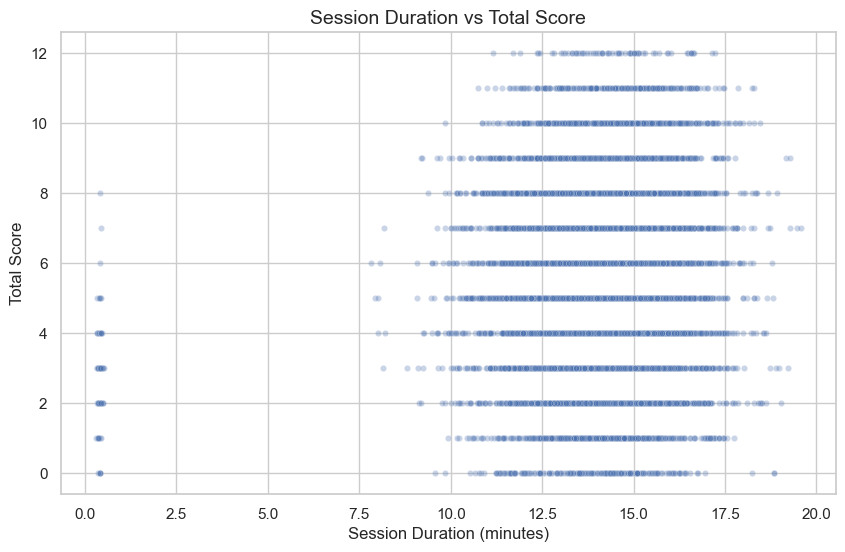

C:\Users\sofya\AppData\Local\Temp\ipykernel_113240\3890382222.py:77: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=task_analysis, x="task_number", y="correct_rate_pct", palette="Reds_r")


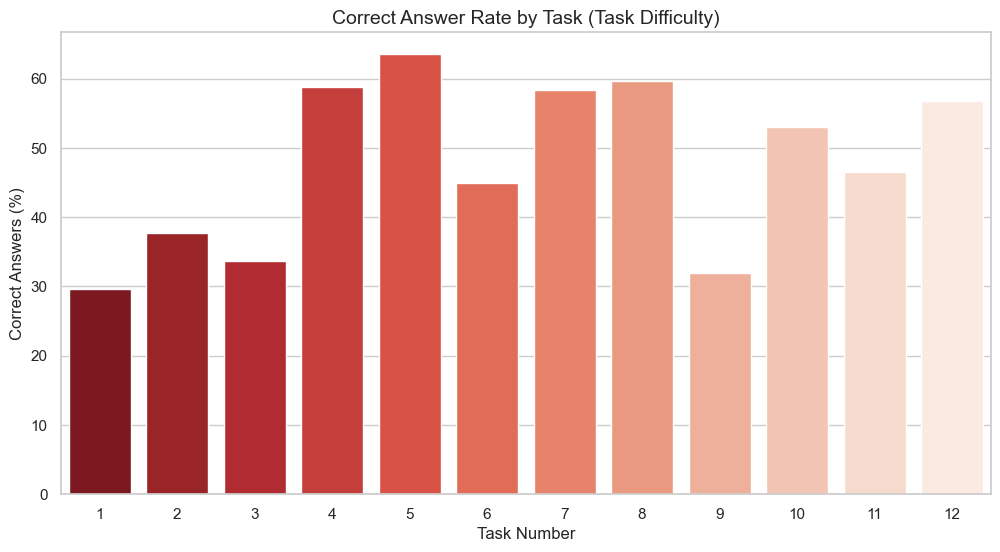

In [37]:
import matplotlib.pyplot as plt
import seaborn as sns
import os
import pandas as pd


os.makedirs("../reports/figures", exist_ok=True)


sns.set_theme(style="whitegrid")


plt.figure(figsize=(10, 6))
sns.histplot(data=df_clean, x="total_score", bins=13, kde=True, color="steelblue")

mean_score = df_clean["total_score"].mean()
median_score = df_clean["total_score"].median()
plt.axvline(mean_score, color='red', linestyle='--', label=f'Mean: {mean_score:.1f}')
plt.axvline(median_score, color='green', linestyle='-', label=f'Median: {median_score:.1f}')

plt.title("Distribution of Olympiad Scores", fontsize=14)
plt.xlabel("Total Score (0-12)", fontsize=12)
plt.ylabel("Number of Participants", fontsize=12)
plt.legend()

plt.savefig("../reports/figures/01_score_distribution.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close() 



plt.figure(figsize=(12, 6))
sns.boxplot(data=df_clean, x="region_clean", y="total_score", palette="Set3")
plt.title("Score Distribution by Region (Anomalies Check)", fontsize=14)
plt.xlabel("Region", fontsize=12)
plt.ylabel("Total Score", fontsize=12)
plt.xticks(rotation=45) # Поворот названий регионов

plt.savefig("../reports/figures/02_boxplot_by_region.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()


region_scores = (
    df_clean.groupby("region_clean")["total_score"]
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

plt.figure(figsize=(12, 6))
sns.barplot(data=region_scores, x="total_score", y="region_clean", palette="viridis")
plt.title("Average Score by Region", fontsize=14)
plt.xlabel("Average Score", fontsize=12)
plt.ylabel("Region", fontsize=12)

plt.savefig("../reports/figures/03_region_scores.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()



plt.figure(figsize=(10, 6))
# alpha=0.3 делает точки полупрозрачными, чтобы видеть плотность
sns.scatterplot(data=df_clean, x="session_duration_min", y="total_score", alpha=0.3, s=20)
plt.title("Session Duration vs Total Score", fontsize=14)
plt.xlabel("Session Duration (minutes)", fontsize=12)
plt.ylabel("Total Score", fontsize=12)

plt.savefig("../reports/figures/04_duration_vs_score.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()



plt.figure(figsize=(12, 6))
sns.barplot(data=task_analysis, x="task_number", y="correct_rate_pct", palette="Reds_r")
plt.title("Correct Answer Rate by Task (Task Difficulty)", fontsize=14)
plt.xlabel("Task Number", fontsize=12)
plt.ylabel("Correct Answers (%)", fontsize=12)

plt.savefig("../reports/figures/05_task_difficulty.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()


по итогам анализа очищенных данных могу сделать следующие выводы:

1. самые сложные задания. если посмотреть на график сложности, то задания под номерами 1 и 2 оказались самыми провальными, с ними справилось меньше всего участников. при этом времени на них ребята тратили довольно много. методистам стоит пересмотреть условия этих задач или дать к ним подсказки на будущий год.

2. лучшие группы участников. статистика четко показывает, что 10 и 11 классы выступили лучше всех. разница между классами значима, и это логично, ведь у старшеклассников больше опыта и багаж знаний. младшим классам нужно больше поддерживающих активностей.

3. регионы. здесь все довольно ровно. несмотря на то, что из москвы и спб участников больше всего, статистической разницы в средних баллах между регионами мы не нашли. это хороший знак, значит олимпиада была честной и задания одинаково понятны школьникам из любого города.

4. аномалии. при очистке я заметила подозрительные сессии. есть ребята, которые завершили олимпиаду меньше чем за минуту, но умудрились набрать приличные баллы. скорее всего это технические сбои таймера или списывание. организаторам стоит проверить такие записи вручную.

5. качество данных. исходная таблица была довольно грязной. там были полные дубликаты строк, куча разных написаний одних и тех же городов (мск, спб, москва) и даже расхождения между заявленным итоговым баллом и суммой баллов за отдельные задания. если бы мы это не почистили, графики бы сильно врали.

6. устройства. телефон это был или компьютер вообще не влияет на результат, разницы нет. а вот время сессии и итоговый балл связаны слабо. то есть просто сидеть над задачей дольше всех не гарантирует высокий балл, но самые быстрые прохождения почти всегда заканчивались провалом.

7. вовлеченность. технических отключений было немного, и они не испортили ребятам итоговые результаты.